<a href="https://colab.research.google.com/github/Manawariqbal/Deep-Learning/blob/main/English_to_urdu_Transalation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install nltk rouge_score -q

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import sparse_categorical_crossentropy
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import Embedding ,GRU, Input, Dense, TimeDistributed, Activation, RepeatVector, Bidirectional,LSTM, Dropout


from sklearn.model_selection import train_test_split
import pickle

In [5]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("zainuddin123/parallel-corpus-for-english-urdu-language")

print("Path to dataset files:", path)

100%|██████████| 419k/419k [00:00<00:00, 498kB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/zainuddin123/parallel-corpus-for-english-urdu-language/versions/1


In [7]:
import os

english_path = os.path.join(path, 'Dataset/english-corpus.txt')
urdu_path = os.path.join(path, 'Dataset/urdu-corpus.txt')

with open(english_path, 'r', encoding='utf-8') as file:
    english_lines = file.readlines()

with open(urdu_path, 'r', encoding='utf-8') as file:
    urdu_lines = file.readlines()

df = pd.DataFrame({'English': english_lines, 'Urdu': urdu_lines})

df['English'] = df['English'].str.strip()
df['Urdu'] = df['Urdu'].str.strip()

display(df.head())

,English,Urdu
0,is zain your nephew,زین تمہارا بھتیجا ہے۔
1,i wish youd trust me,کاش تم مجھ پر بھروسہ کرتے
2,did he touch you,کیا اس نے آپ کو چھوا؟
3,its part of life,اس کی زندگی کا حصہ
4,zain isnt ugly,زین بدصورت نہیں ہے۔


In [8]:
eng = df['English']
urdu = df['Urdu']

In [9]:
# Tokenizing Urdu sentences
urdu_tokenizer = Tokenizer()
urdu_tokenizer.fit_on_texts(df['Urdu'])
tokenized_urdu_sentences = urdu_tokenizer.texts_to_sequences(df['Urdu'])

# Tokenizing English sentences
english_tokenizer = Tokenizer()
english_tokenizer.fit_on_texts(df['English'])
tokenized_english_sentences = english_tokenizer.texts_to_sequences(df['English'])


# Padding Urdu sentences
preproc_urdu_sentences = pad_sequences(tokenized_urdu_sentences, maxlen=50, padding='post')

# Padding English sentences
preproc_english_sentences = pad_sequences(tokenized_english_sentences, maxlen=50, padding='post')

In [10]:
df['English'][:5]

,English
0,is zain your nephew
1,i wish youd trust me
2,did he touch you
3,its part of life
4,zain isnt ugly


In [11]:
preproc_english_sentences[:5]

array([[   2,    4,   22, 2336,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0],
       [   1,  222,  689,  274,   12,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0],
       [  30,    6,  478,    3,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,   

In [12]:
# Defining model parameters
learning_rate = 0.001
# input_shape = preproc_english_sentences.shape
# output_sequence_length = preproc_urdu_sentences.shape[1]
urdu_vocab_size = len(urdu_tokenizer.word_index) + 1
english_vocab_size = len(english_tokenizer.word_index) + 1

In [13]:
# Creating the model
model = Sequential()
model.add(Embedding(english_vocab_size, 256))
model.add(Bidirectional(GRU(256, return_sequences=True)))
model.add(TimeDistributed(Dense(1024, activation='leaky_relu')))
model.add(Dropout(0.5))
model.add(TimeDistributed(Dense(urdu_vocab_size, activation='softmax')))

# Compiling the model
model.compile(loss=sparse_categorical_crossentropy,
              optimizer=Adam(learning_rate),
              metrics=['accuracy'])

# Adding Early Stopping
early_stopping = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

# Training the model with Early Stopping
history = model.fit(preproc_english_sentences, preproc_urdu_sentences,
                    batch_size=64,
                    epochs=100,
                    validation_split=0.3,
                    callbacks=[early_stopping])

Epoch 1/100
269/269 ━━━━━━━━━━━━━━━━━━━━ 50s 138ms/step - accuracy: 0.9024 - loss: 0.7627 - val_accuracy: 0.9137 - val_loss: 0.5640
Epoch 2/100
269/269 ━━━━━━━━━━━━━━━━━━━━ 37s 136ms/step - accuracy: 0.9158 - loss: 0.5352 - val_accuracy: 0.9184 - val_loss: 0.5190
Epoch 3/100
269/269 ━━━━━━━━━━━━━━━━━━━━ 37s 138ms/step - accuracy: 0.9209 - loss: 0.4803 - val_accuracy: 0.9233 - val_loss: 0.4737
Epoch 4/100
269/269 ━━━━━━━━━━━━━━━━━━━━ 38s 141ms/step - accuracy: 0.9259 - loss: 0.4264 - val_accuracy: 0.9274 - val_loss: 0.4358
Epoch 5/100
269/269 ━━━━━━━━━━━━━━━━━━━━ 37s 139ms/step - accuracy: 0.9305 - loss: 0.3759 - val_accuracy: 0.9308 - val_loss: 0.4119
Epoch 6/100
269/269 ━━━━━━━━━━━━━━━━━━━━ 38s 140ms/step - accuracy: 0.9349 - loss: 0.3328 - val_accuracy: 0.9336 - val_loss: 0.3887
Epoch 7/100
269/269 ━━━━━━━━━━━━━━━━━━━━ 38s 140ms/step - accuracy: 0.9391 - loss: 0.2934 - val_accuracy: 0.9360 - val_loss: 0.3708
Epoch 8/100
269/269 ━━━━━━━━━━━━━━━━━━━━ 38s 140ms/step - accuracy: 0.9429 -

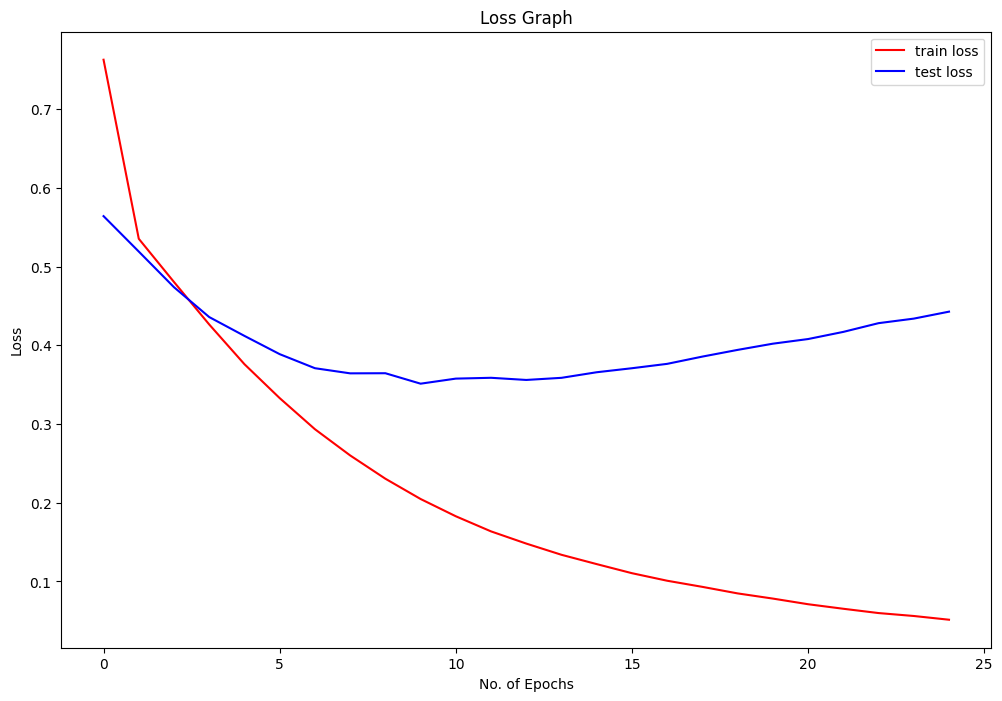

In [14]:
plt.figure(figsize=(12,8))
plt.plot(history.history['loss'],'r',label='train loss')
plt.plot(history.history['val_loss'],'b',label='test loss')
plt.xlabel('No. of Epochs')
plt.ylabel('Loss')
plt.title('Loss Graph')
plt.legend();

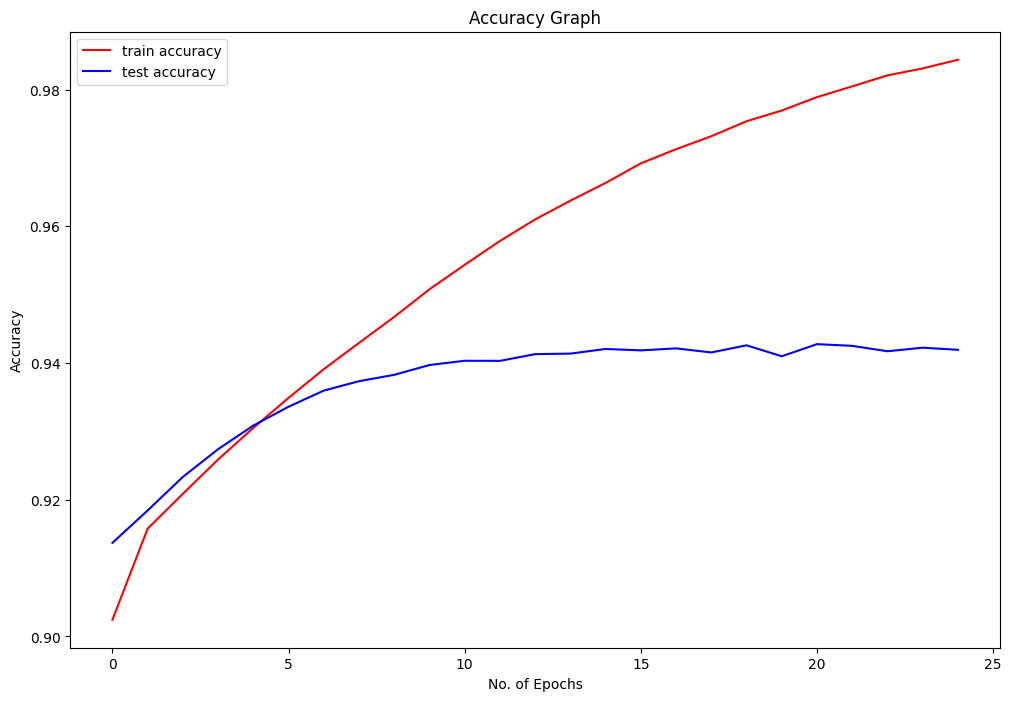

In [15]:
plt.figure(figsize=(12,8))
plt.plot(history.history['accuracy'],'r',label='train accuracy')
plt.plot(history.history['val_accuracy'],'b',label='test accuracy')
plt.xlabel('No. of Epochs')
plt.ylabel('Accuracy')
plt.title('Accuracy Graph')
plt.legend();

In [17]:
# Saving the model
model.save('english_to_urdu_translator_final.h5')

pickle.dump(english_tokenizer,open("english_tokenizer.pkl",'wb'))
pickle.dump(urdu_tokenizer,open("urdu_tokenizer.pkl",'wb'))

In [19]:
# Load the trained model
model = load_model('english_to_urdu_translator_final.h5')

# Load tokenizers
with open('english_tokenizer.pkl', 'rb') as file:
    english_tokenizer = pickle.load(file)

with open('urdu_tokenizer.pkl', 'rb') as file:
    urdu_tokenizer = pickle.load(file)

# Reverse mapping for Urdu tokenizer (index to word)
urdu_index_to_word = {index: word for word, index in urdu_tokenizer.word_index.items()}

def translate_sentences(sentences):
    # Tokenize input sentences
    sequences = english_tokenizer.texts_to_sequences(sentences)

    # Pad the sequences
    padded_sequences = pad_sequences(sequences, maxlen=50, padding='post')

    # Predict Urdu sentences
    predictions = model.predict(padded_sequences)

    translated_sentences = []
    for prediction in predictions:
        predicted_words = [urdu_index_to_word.get(np.argmax(word_vec), '') for word_vec in prediction]
        translated_sentence = ' '.join(predicted_words).strip()
        translated_sentences.append(translated_sentence)

    return translated_sentences

# Sample 10 English sentences
english_sentences = [
    "is zain your nephew",
    "i wish youd trust me",
    "did he touch you",
    "its part of life",
    "zain isnt ugly",
    "i am in a hurry today",
    "take this medicine",
    "this is the case",
    "zains tipsy",
    "I love you"
]

# Translate and print results
urdu_translations = translate_sentences(english_sentences)

for eng, urdu in zip(english_sentences, urdu_translations):
    print(f"English: {eng}\nUrdu: {urdu}\n")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 954ms/step
English: is zain your nephew
Urdu: زین تمہارا بھتیجا ہے

English: i wish youd trust me
Urdu: کاش آپ مجھ پر بھروسہ بھروسہ

English: did he touch you
Urdu: کیا اسے نے آپ کو دیکھا

English: its part of life
Urdu: اس کا کا کا ہے

English: zain isnt ugly
Urdu: زین بدصورت نہیں ہے

English: i am in a hurry today
Urdu: میں ایک میں میں

English: take this medicine
Urdu: اسے لے لے

English: this is the case
Urdu: یہ معاملہ ہے

English: zains tipsy
Urdu: زین غائب

English: I love you
Urdu: مجھے تم سے محبت کرتا

